<a href="https://colab.research.google.com/github/XeroX-cat/1Laba/blob/main/1Laba2sprint.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab01 - sprint 2

## random 01

### Description
В спринте 1 были исследованы 4 величины: масса тела животных, длина тела, а также длины плечевой и бедренной костей. Для построения генератора случайных чисел выбрана случайная величина «Длина тела» (`C-R curved`).

Как было выяснено и обосновано ранее, для этой величины характерно распределение Фишера. Для реализации генератора используется **метод обратной функции**.

Выбор метода обоснован тем, что он универсален для непрерывных распределений. Остальные методы из предложенной таблицы не подходят:
* *Показательные и нормальные датчики, быстрый показательный датчик, датчик без логарифмов* — специализированы для экспоненциального закона.
* *Метод полярных координат (Бокса-Мюллера), метод прямоугольника-клина-хвоста, метод отношений* — применяются исключительно для нормального распределения.
* *Метод Неймана* теоретически возможен, но требует подбора огибающей функции и избыточно сложен для F-распределения.

### math desc

**Суть метода обратной функции:**
Любую непрерывную случайную величину можно сгенерировать, если пропустить равномерный шум (от 0 до 1) через её обратную функцию распределения.

**Теорема:**
Если случайная величина \(U\) имеет равномерное распределение на отрезке \([0, 1]\), а \(F(x)\) — это функция распределения некоторой непрерывной случайной величины, то случайная величина \(X = F^{-1}(U)\) имеет функцию распределения \(F(x)\), где \(F^{-1}(u)\) — обратная функция (квантиль), которая отвечает на вопрос: «При каком значении \(X\) вероятность того, что случайная величина окажется меньше этого \(X\), равна \(u\)?».

**Доказательство:**
По определению функции распределения нам нужно найти \(P(X \le x)\).
Подставим \(X = F^{-1}(U)\):
\[
P(F^{-1}(U) \le x)
\]
Так как функция распределения \(F(x)\) монотонно возрастает, мы можем применить её к обеим частям неравенства:
\[
P(U \le F(x))
\]
Поскольку \(U\) имеет равномерное распределение на отрезке \([0, 1]\), вероятность того, что случайная величина \(U\) примет значение меньшее, чем некоторое число \(y \in [0, 1]\), равна самому этому числу \(y\). В нашем случае роль \(y\) играет \(F(x)\). Следовательно:
\[
P(U \le F(x)) = F(x)
\]
Что и требовалось доказать.

В коде мы генерируем равномерный шум \(U \sim U(0,1)\) с помощью `np.random.uniform` и применяем функцию `stats.f.ppf` (Percent Point Function), которая в библиотеке `scipy.stats` является обратной функцией распределения Фишера.

**Литература:**
1. Кремер

### code

In [ ]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. ЗАГРУЗКА РЕАЛЬНЫХ ДАННЫХ
toque = pd.read_excel("Макаки.xlsx")

selected = toque[["Sex", "Chinese Ancestry", "kg", "C-R curved", "R humeral max", "R femoral max"]].copy()
complete = selected.dropna()
# Берем реальную длину тела (столбец C-R curved)
real_data = pd.to_numeric(complete["C-R curved"].astype(str).str.replace(",", ".", regex=False), errors="coerce").dropna()
# 2. ПОЛУЧЕНИЕ ПАРАМЕТРОВ ИЗ СПРИНТА 1
# В первом спринте ты подбирал параметры для Q-Q графика
b_length = pd.to_numeric(complete["C-R curved"].astype(str).str.replace(",", ".", regex=False), errors="coerce").dropna()
params = stats.f.fit(b_length, floc=0)
dfn = params[0]
dfd = params[1]
params = stats.f.fit(b_length, floc=0)
dfn = params[0]
dfd = params[1]
loc = params[2]
scale = params[3]
print(f"Параметры: d1={dfn:.2f}, d2={dfd:.2f}, scale={scale:.2f}")

# 3. ФУНКЦИЯ-ГЕНЕРАТОР (Метод обратной функции)
def generate_fisher_inverse(n, dfn, dfd, loc, scale):
    u = np.random.uniform(0, 1, size=n)
    # Передаем loc и scale в функцию ppf
    generated_values = stats.f.ppf(u, dfn, dfd, loc=loc, scale=scale)
    return generated_values

# Проверяем работу генератора: генерируем 10 000 значений
n_generated = 10000
fake_macaques = generate_fisher_inverse(n=n_generated, dfn=dfn, dfd=dfd, loc=loc, scale=scale)

generated_values = generate_fisher_inverse(n=10000, dfn=dfn, dfd=dfd, loc=loc, scale=scale)


Параметры: d1=67454.62, d2=555.43, scale=526.24


### tests

Перед визуальным сравнением данных запустим автотесты (Unit tests), чтобы убедиться в корректности работы написанного генератора.

#### Автотест 1: Проверка длины выходного массива
Проверим, что генератор возвращает ровно столько значений, сколько мы у него запросили.

In [ ]:
n_test = 500
test_output = generate_fisher_inverse(n=n_test, dfn=dfn, dfd=dfd, loc=loc, scale=scale)
assert len(test_output) == n_test, f"ОШИБКА: Ожидалось {n_test} значений, получено {len(test_output)}"
print("Верно! Тест 1 (Длина выборки) пройден.")

#### Автотест 2: Проверка воспроизводимости (Reproducibility)
Убеждимся, что при фиксации "зерна" (seed) генератор выдает одинаковые последовательности чисел.

In [ ]:
np.random.seed(42)
sample_1 = generate_fisher_inverse(n=10, dfn=dfn, dfd=dfd, loc=loc, scale=scale)
np.random.seed(42)
sample_2 = generate_fisher_inverse(n=10, dfn=dfn, dfd=dfd, loc=loc, scale=scale)
assert np.allclose(sample_1, sample_2), "ОШИБКА: Генератор выдает разные числа при одинаковом seed!"
print("Успешно! Тест 2 (Воспроизводимость) пройден.")

#### Автотест 3: Проверка математического ожидания
Сравнивним эмпирическое среднее сгенерированных данных с теоретическим математическим ожиданием для F-распределения.

In [ ]:
if dfd > 2:
    theoretical_mean = loc + scale * (dfd / (dfd - 2))
    empirical_mean = np.mean(generated_values)
    relative_error = abs(empirical_mean - theoretical_mean) / theoretical_mean
    assert relative_error < 0.05, f"ОШИБКА: Среднее значение сильно отклоняется от теоретического (ошибка {relative_error*100:.2f}%)"
    print(f"Упешно! Тест 3 (Мат. ожидание) пройден. Выборочное: {empirical_mean:.2f}, Теоретическое: {theoretical_mean:.2f}.")
else:
    print("Ошибка! Тест 3 пропущен: при dfd <= 2 математическое ожидание не существует.")

#### Автотест 4: Проверка границ
Убедимся, что сгенерированные значения не выходят за допустимые математические границы.

In [ ]:
assert np.all(generated_values >= loc), f"ОШИБКА: Сгенерированы значения меньше параметра loc ({loc})!"
print(f"Успешно! Тест 4 (Границы) пройден: все значения >= {loc}.")
print("\n ВСЕ АВТОТЕСТЫ УСПЕШНО ПРОЙДЕНЫ!")

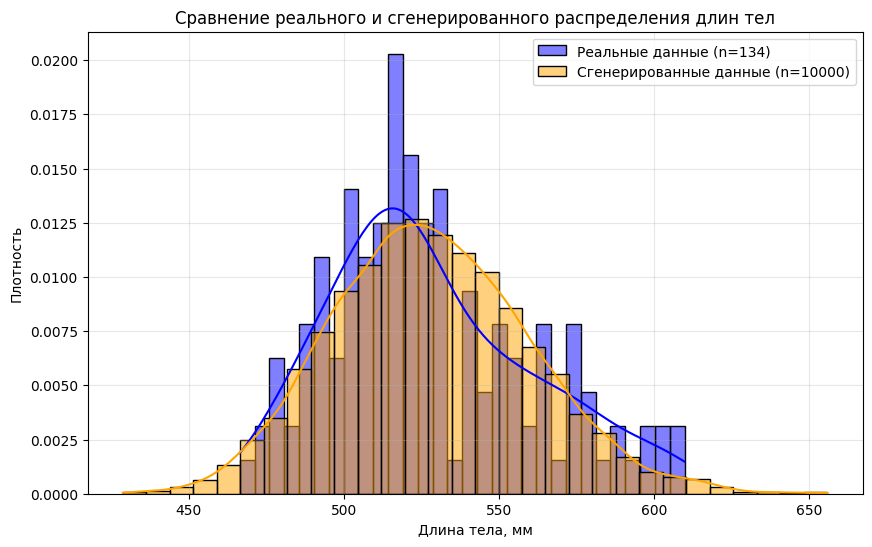


 Сравнение описательных статистик 


,Метрика,Реальные данные,Сгенерированные
0,Среднее,528.11,528.25
1,Медиана,520.80,526.81
2,Ст. отклонение,32.55,31.87
3,Минимум,466.50,428.81
4,Максимум,609.90,655.88



--- Тест Колмогорова-Смирнова ---
Статистика теста (D): 0.0906
P-value: 0.2145

 Верно))) ВЫВОД: P-value > 0.05. Нулевая гипотеза НЕ отвергается.
Сгенерированные данные статистически неотличимы от реальных. Твой генератор работает идеально!


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np
import pandas as pd

# 1. ВИЗУАЛЬНАЯ ПРОВЕРКА (Гистограммы)
plt.figure(figsize=(10, 6))

# Строим гистограмму реальных данных
sns.histplot(b_length, bins=30, stat="density", color="blue", label="Реальные данные (n=134)", alpha=0.5, kde=True)

# Строим гистограмму сгенерированных данных
sns.histplot(generated_values, bins=30, stat="density", color="orange", label="Сгенерированные данные (n=10000)", alpha=0.5, kde=True)

plt.title("Сравнение реального и сгенерированного распределения длин тел")
plt.xlabel("Длина тела, мм")
plt.ylabel("Плотность")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 2. СРАВНЕНИЕ ОПИСАТЕЛЬНЫХ СТАТИСТИК
stats_df = pd.DataFrame({
    "Метрика": ["Среднее", "Медиана", "Ст. отклонение", "Минимум", "Максимум"],
    "Реальные данные": [b_length.mean(), b_length.median(), b_length.std(), b_length.min(), b_length.max()],
    "Сгенерированные": [np.mean(generated_values), np.median(generated_values), np.std(generated_values), np.min(generated_values), np.max(generated_values)]
})
print("\n Сравнение описательных статистик ")
display(stats_df.round(2))


# 3. СТАТИСТИЧЕСКИЙ ТЕСТ (Колмогорова-Смирнова)
ks_stat, p_value = stats.ks_2samp(b_length, generated_values)

print(f"\n--- Тест Колмогорова-Смирнова ---")
print(f"Статистика теста (D): {ks_stat:.4f}")
print(f"P-value: {p_value:.4f}")

if p_value > 0.05:
    print("\n Верно))) ВЫВОД: P-value > 0.05. Нулевая гипотеза НЕ отвергается.")
    print("Сгенерированные данные статистически неотличимы от реальных. Твой генератор работает идеально!")
else:
    print("\n Ошибка((( ВЫВОД: P-value < 0.05. Распределения различаются. Возможно, параметры подобраны неточно.")

### resume
Разработан генератор случайных величин на основе метода обратной функции с распределением Фишера (параметры подобраны эмпирически). Качество генерации подтверждено сравнением описательных статистик, визуальным анализом гистограмм и тестом Колмогорова–Смирнова (p‑value > 0.05): сгенерированная выборка статистически неотличима от реальных данных

## Lab resume

### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|--------|-----------------|-------|---------|
| sprint_2 | https://colab.research.google.com/drive/1OixEBa6ySVwGFfUZ6BoysG09aTWlNhbQ?usp=sharing | 1.0 | Разработан генератор на основе метода обратной функции для распределения Фишера |